![Python Banner](../../Image/05_04_doubleML.png)


# 4.2 Double ML - Single/multiple Treatment

Double Machine Learning (DML) fits outcome and treatment with flexible ML, then regresses outcome residuals on treatment residuals to estimate the conditional average treatment effect (CATE). **PyCausalML** provides:

- **LinearDML**: ordinary least squares final stage for heterogeneous treatment effects.
- **SparseLinearDML**: Lasso final stage (for a high-dimensional set of effect modifiers).
- **NonParamDML**: a flexible final stage on the R-learner pseudo-outcome.
- **CausalForestDML**: a random forest on the doubly robust pseudo-outcome for a binary treatment.
- **KernelDML**: a random-Fourier approximation of a kernel CATE for a binary treatment.

This notebook follows the structure of the [EconML DML examples](https://github.com/py-why/EconML/blob/main/notebooks/Double%20Machine%20Learning%20Examples.ipynb). Section 6 applies the same estimators to the NMES sample in `Data/nmes_data.csv`.


## Overview

`LinearDML`, `SparseLinearDML`, and `NonParamDML` / `CausalForestDML` are variants of DML for heterogeneous treatment effects: $\theta(X)$ may vary across individuals, rather than being a single constant $\theta_0$.

The shared backbone is the same: residualize $Y$ and $D$ with ML nuisance models, then estimate the treatment effect from the residuals. What differs is how the final stage models $\theta(X)$.

### The shared setup

$$Y = \theta(X) \cdot D + g_0(X) + \varepsilon$$

After partialling out nuisances:

$$\tilde{Y} = Y - \hat{\ell}(X), \qquad \tilde{D} = D - \hat{m}(X)$$

$$\tilde{Y} = \theta(X) \cdot \tilde{D} + \text{noise}$$

### LinearDML

$\theta(X) = \beta_0 + \beta_1 Z_1 + \beta_2 Z_2 + \cdots$. The final stage is OLS of $\tilde{Y}$ on $\tilde{D}$ interacted with the effect modifiers. Use it when you want interpretable coefficients and can defend a linear specification.

### SparseLinearDML

The same linear CATE, with an L1 penalty, when many candidate modifiers are zero. Use it when the modifier list is long.

### NonParamDML and CausalForestDML

The final stage is a flexible regression of the orthogonal pseudo-outcome. `CausalForestDML` is the binary-treatment version whose final stage is a random forest. `NonParamDML` accepts a continuous treatment.


## Implementation in Python

The sections below use PyCausalML for a single continuous treatment, a single binary treatment, polynomial features, observational NMES data, and two continuous treatments at once.

**Contents**

1. Single continuous treatment (synthetic) and model selection
2. Single binary treatment (synthetic) and ATE inference
3. Single continuous treatment with polynomial features
4. Single continuous treatment on NMES
5. Multiple continuous treatments on NMES
6. Use case: compare `LinearDML`, `SparseLinearDML`, and `NonParamDML` on NMES, with SHAP


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


In [3]:
def cross_fit_predict(X, y, n_splits, seed, kind="ridge"):
    """Out-of-fold predictions. kind is 'ridge', 'rf', or 'gbr'."""
    pred = np.zeros(len(y), dtype=float)
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, dtype=float)
    for fold, (tr, te) in enumerate(splitter.split(X)):
        model = _nuisance(kind, seed + fold)
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    return pred


def _nuisance(kind, seed):
    if kind == "ridge":
        return Ridge(alpha=1.0)
    if kind == "lasso":
        return Lasso(alpha=0.02, max_iter=8000)
    if kind == "rf":
        return RandomForestRegressor(
            n_estimators=40, max_depth=4, min_samples_leaf=5, random_state=seed, n_jobs=1,
        )
    if kind == "gbr":
        return GradientBoostingRegressor(
            n_estimators=40, max_depth=2, learning_rate=0.08, random_state=seed,
        )
    raise ValueError(kind)


def plot_beeswarm(explanation, title, max_display=8):
    imp = explanation.importance()
    order = np.argsort(imp)[-max_display:]
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(order) + 1.3))
    rng = np.random.default_rng(0)
    for i, j in enumerate(order):
        vals = explanation.values[:, j]
        raw = explanation.data[:, j]
        span = float(np.ptp(raw)) or 1.0
        color = (raw - np.min(raw)) / span
        jitter = rng.uniform(-0.16, 0.16, size=len(vals))
        ax.scatter(vals, np.full(len(vals), i) + jitter, c=color, cmap="coolwarm", s=18, alpha=0.9)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels([explanation.feature_names[j] for j in order])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("SHAP value")
    ax.set_title(title)
    fig.tight_layout()
    return fig


print("Helpers ready")


Helpers ready


## 1. Single Continuous Treatment (Synthetic) and Model Selection

### 1.1 Data-generating process

The DGP follows Chernozhukov et al.:

$$T = \langle W, \beta\rangle + \eta$$

$$Y = T\cdot \theta(X) + \langle W, \gamma\rangle + \epsilon$$

with $\theta(x) = \exp(2 x_1)$. Confounders $W$ and the effect modifier $X$ are independent. The treatment stays continuous; `LinearDML(..., discrete_treatment=False)` residualizes it with a regression nuisance.


In [4]:
def dgp_continuous(n=1800, n_w=6, rng=None):
    rng = np.random.default_rng(0 if rng is None else rng)
    x = rng.uniform(0, 1, size=(n, 1))
    w = rng.normal(size=(n, n_w))
    beta = np.array([0.5, 0.35, 0.25, -0.2, 0.15, -0.1])[:n_w]
    gamma = np.array([0.4, -0.3, 0.25, 0.15, -0.2, 0.1])[:n_w]
    theta = np.exp(2.0 * x[:, 0])
    treatment = w @ beta + rng.normal(scale=0.6, size=n)
    outcome = treatment * theta + w @ gamma + rng.normal(size=n)
    return x, w, treatment, outcome, theta


def design(x, w):
    names = ["x1"] + [f"W{j + 1}" for j in range(w.shape[1])]
    return np.column_stack([x, w]), names


rng = np.random.default_rng(7)
x, w, treatment, outcome, theta_true = dgp_continuous(rng=rng)
X, x_names = design(x, w)
hold = rng.choice(len(X), size=int(0.3 * len(X)), replace=False)
train = np.setdiff1d(np.arange(len(X)), hold)
print("Train", len(train), "Test", len(hold), "true CATE mean", round(float(theta_true.mean()), 3))


Train 1260 Test 540 true CATE mean 3.165


### 1.2 Train estimators

We compare **LinearDML**, **SparseLinearDML** on a degree-3 polynomial of $x_1$ plus $W$, **SparseLinearDML** on a degree-6 polynomial, and **NonParamDML** with a random-forest final stage.


In [5]:
def poly_design(x, w, degree):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    xp = poly.fit_transform(x)
    names = [f"x1^{p}" for p in range(1, degree + 1)] + [f"W{j + 1}" for j in range(w.shape[1])]
    return np.column_stack([xp, w]), names


est = LinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", random_state=1)
est.fit(X[train], treatment[train], outcome[train], feature_names=x_names)

X3, names3 = poly_design(x, w, 3)
est1 = SparseLinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", alpha=0.05, random_state=1)
est1.fit(X3[train], treatment[train], outcome[train], feature_names=names3)

X6, names6 = poly_design(x, w, 6)
est2 = SparseLinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", alpha=0.2, random_state=1)
est2.fit(X6[train], treatment[train], outcome[train], feature_names=names6)

est_np = NonParamDML(
    discrete_treatment=False, n_splits=2, model_y="gbr", model_final="rf", n_estimators=40, random_state=1,
)
est_np.fit(X[train], treatment[train], outcome[train], feature_names=x_names)
print("Fitted LinearDML, two SparseLinearDML specifications, and NonParamDML")


Fitted LinearDML, two SparseLinearDML specifications, and NonParamDML


### 1.3 Performance visualization


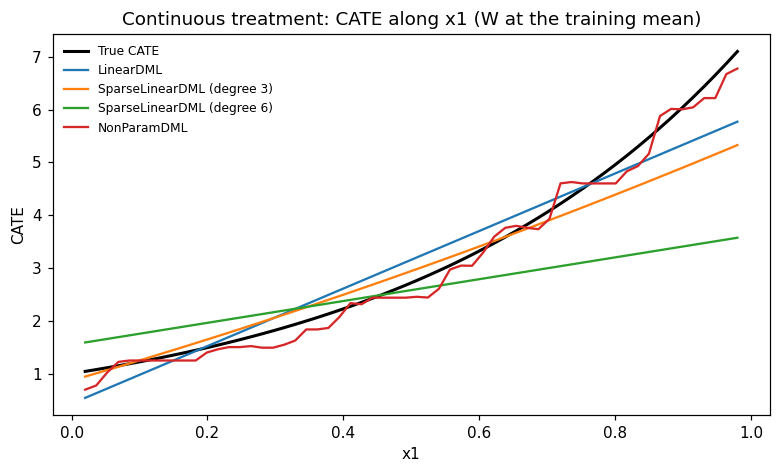

In [6]:
w_bar = w[train].mean(axis=0)
grid = np.linspace(0.02, 0.98, 60).reshape(-1, 1)
w_grid = np.repeat(w_bar.reshape(1, -1), len(grid), axis=0)
Xg, _ = design(grid, w_grid)
Xg3, _ = poly_design(grid, w_grid, 3)
Xg6, _ = poly_design(grid, w_grid, 6)
truth = np.exp(2.0 * grid[:, 0])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(grid[:, 0], truth, color="black", lw=2, label="True CATE")
ax.plot(grid[:, 0], est.predict(Xg), label="LinearDML")
ax.plot(grid[:, 0], est1.predict(Xg3), label="SparseLinearDML (degree 3)")
ax.plot(grid[:, 0], est2.predict(Xg6), label="SparseLinearDML (degree 6)")
ax.plot(grid[:, 0], est_np.predict(Xg), label="NonParamDML")
ax.set_xlabel("x1")
ax.set_ylabel("CATE")
ax.set_title("Continuous treatment: CATE along x1 (W at the training mean)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


### 1.4 Model selection

Mean squared error of the predicted CATE against the true CATE on the test sample. Lower is better.


In [7]:
scores = {
    "LinearDML": np.mean((est.predict(X[hold]) - theta_true[hold]) ** 2),
    "SparseLinearDML degree 3": np.mean((est1.predict(X3[hold]) - theta_true[hold]) ** 2),
    "SparseLinearDML degree 6": np.mean((est2.predict(X6[hold]) - theta_true[hold]) ** 2),
    "NonParamDML": np.mean((est_np.predict(X[hold]) - theta_true[hold]) ** 2),
}
pd.DataFrame({"Test CATE MSE": scores}).round(4).sort_values("Test CATE MSE")


,Test CATE MSE
NonParamDML,0.0960
LinearDML,0.2521
SparseLinearDML degree 3,0.3403
SparseLinearDML degree 6,1.8287


## 2. Single Binary Treatment (Synthetic) and ATE

### 2.1 Data-generating process

$$T \sim \text{Bernoulli}(\sigma(\langle W, \beta\rangle))$$

$$Y = T\cdot \theta(X) + \langle W, \gamma\rangle + \epsilon$$

with the same $\theta(x) = \exp(2 x_1)$.


In [8]:
def dgp_binary(n=1800, n_w=6, rng=None):
    rng = np.random.default_rng(1 if rng is None else rng)
    x = rng.uniform(0, 1, size=(n, 1))
    w = rng.normal(size=(n, n_w))
    beta = np.array([0.4, 0.3, -0.2, 0.2, 0.1, -0.1])[:n_w]
    gamma = np.array([0.3, -0.25, 0.2, 0.1, -0.15, 0.05])[:n_w]
    theta = np.exp(2.0 * x[:, 0])
    propensity = 1.0 / (1.0 + np.exp(-(w @ beta)))
    treatment = rng.binomial(1, propensity).astype(float)
    outcome = treatment * theta + w @ gamma + rng.normal(size=n)
    return x, w, treatment, outcome, theta


rng_b = np.random.default_rng(11)
xb, wb, tb, yb, thetab = dgp_binary(rng=rng_b)
Xb, names_b = design(xb, wb)
hold_b = rng_b.choice(len(Xb), size=int(0.3 * len(Xb)), replace=False)
train_b = np.setdiff1d(np.arange(len(Xb)), hold_b)
print("Treated share", round(float(tb.mean()), 3))


Treated share 0.514


### 2.2 Train estimators (binary treatment)


In [9]:
lin_b = LinearDML(discrete_treatment=True, n_splits=2, model_y="rf", n_estimators=40, random_state=2)
lin_b.fit(Xb[train_b], tb[train_b], yb[train_b], feature_names=names_b)
cf_b = CausalForestDML(num_trees=60, n_splits=2, random_state=2)
cf_b.fit(Xb[train_b], tb[train_b], yb[train_b], feature_names=names_b)
irm_b = InteractiveRegressionDML(n_splits=2, model_y="rf", n_estimators=40, random_state=2)
irm_b.fit(Xb[train_b], tb[train_b], yb[train_b], feature_names=names_b)
ker_b = KernelDML(n_components=25, n_splits=2, random_state=2)
ker_b.fit(Xb[train_b], tb[train_b], yb[train_b], feature_names=names_b)
print("Binary-treatment models fitted")


Binary-treatment models fitted


### 2.3 Visualization and ATE

Pointwise intervals are not part of these estimators. The plot shows the CATE along $x_1$. The table is the average effect, with the influence-function interval from each model, next to the mean of the true CATE on the test sample.


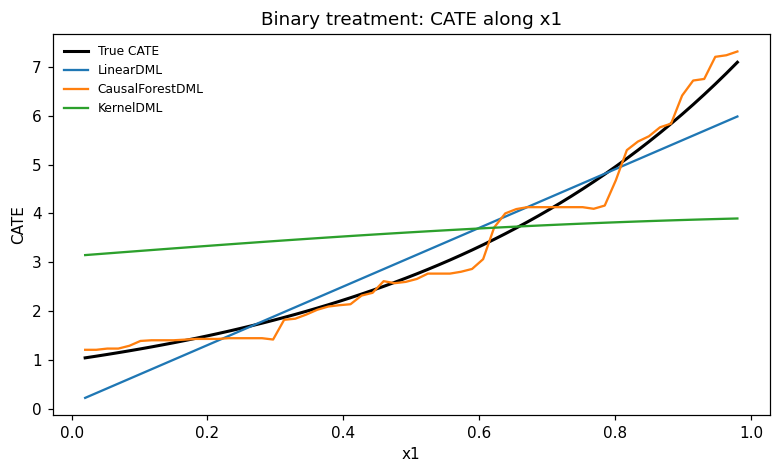

In [10]:
wg = np.repeat(wb[train_b].mean(axis=0).reshape(1, -1), len(grid), axis=0)
Xbg, _ = design(grid, wg)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(grid[:, 0], np.exp(2 * grid[:, 0]), color="black", lw=2, label="True CATE")
ax.plot(grid[:, 0], lin_b.predict(Xbg), label="LinearDML")
ax.plot(grid[:, 0], cf_b.predict(Xbg), label="CausalForestDML")
ax.plot(grid[:, 0], ker_b.predict(Xbg), label="KernelDML")
ax.set_xlabel("x1")
ax.set_ylabel("CATE")
ax.set_title("Binary treatment: CATE along x1")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


In [11]:
rows = []
for name, model in [("LinearDML", lin_b), ("CausalForestDML", cf_b), ("InteractiveRegressionDML", irm_b), ("KernelDML", ker_b)]:
    summary = model.average_treatment_effect()
    rows.append({"Model": name, **{k: round(float(summary[k]), 3) for k in summary}})
rows.append({"Model": "True mean CATE (test)", "estimate": round(float(thetab[hold_b].mean()), 3)})
pd.DataFrame(rows)


,Model,estimate,std.err,ci_lower,ci_upper
0,LinearDML,3.048,0.069,2.913,3.182
1,CausalForestDML,3.140,0.079,NaN,NaN
2,InteractiveRegressionDML,3.130,0.079,2.976,3.284
3,KernelDML,3.079,0.081,NaN,NaN
4,True mean CATE (test),3.144,NaN,NaN,NaN


## 3. Single Continuous Treatment with Polynomial Features

Section 1 already fit three linear final stages. Here $\hat{\theta}(z) = \hat{\beta}_0 + z^\top \hat{\beta}$, where $z$ is a row of the design passed to `fit`. `intercept_` is $\hat{\beta}_0$ and `feature_coef_` is $\hat{\beta}$.

### 3.1 Coefficients and intercept


In [12]:
coef_table = pd.DataFrame({"feature": x_names, "LinearDML": est.feature_coef_})
print("LinearDML intercept:", round(float(est.intercept_), 4))
coef_table.round(4)


LinearDML intercept: 0.4252


,feature,LinearDML
0,x1,5.4483
1,W1,-0.0512
2,W2,-0.0210
3,W3,-0.0639
4,W4,-0.0859
5,W5,-0.1453
6,W6,0.1030


### 3.2 Worked example: CATE from coefficients vs `predict`

For `LinearDML` the reconstruction $\hat{\beta}_0 + z^\top\hat{\beta}$ matches `predict`. For `SparseLinearDML` the same identity holds: the Lasso is fit without an extra intercept on top of the column of ones inside the residual design.


In [13]:
recon = est.intercept_ + X[hold] @ est.feature_coef_
direct = est.predict(X[hold])
recon_s = est1.intercept_ + X3[hold] @ est1.feature_coef_
direct_s = est1.predict(X3[hold])
print("LinearDML max |reconstructed - predict|:", float(np.max(np.abs(recon - direct))))
print("SparseLinearDML max |reconstructed - predict|:", float(np.max(np.abs(recon_s - direct_s))))


LinearDML max |reconstructed - predict|: 0.0
SparseLinearDML max |reconstructed - predict|: 0.0


## 4. Single Continuous Treatment (Observational Data)

The observational example uses the 1987 National Medical Expenditure Survey extract in `Data/nmes_data.csv`. The outcome is `TOTALEXP` and the continuous treatment is `packyears`. The remaining columns are covariates.


In [14]:
nmes = pd.read_csv(data_dir / "nmes_data.csv").dropna().reset_index(drop=True)
if len(nmes) > 3000:
    nmes = nmes.sample(3000, random_state=21).reset_index(drop=True)
y_nmes = nmes["TOTALEXP"].to_numpy(dtype=float)
t_pack = nmes["packyears"].to_numpy(dtype=float)
x_nmes_cols = [c for c in nmes.columns if c not in {"TOTALEXP", "packyears"}]
X_nmes = nmes[x_nmes_cols].to_numpy(dtype=float)
lin_nmes = LinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", random_state=4)
lin_nmes.fit(X_nmes, t_pack, y_nmes, feature_names=x_nmes_cols)
print(nmes.shape)
print(lin_nmes.average_treatment_effect())


(3000, 12)
{'estimate': 8.909333639785666, 'std.err': 5.911920192792046, 'ci_lower': -2.6778170175618357, 'ci_upper': 20.49648429713317}


## 5. Multiple Continuous Treatments (Observational)

Two continuous exposures, `packyears` and `AGESMOKE`, enter a joint residual-on-residual regression. Cross-fitted residuals of $Y$ are regressed on the cross-fitted residuals of both treatments, which is the constant-effect version of a multi-treatment final stage. Each column also gets its own `LinearDML` so the marginal CATE can vary with $X$.


In [15]:
t_age = nmes["AGESMOKE"].to_numpy(dtype=float)
x_multi_cols = [c for c in nmes.columns if c not in {"TOTALEXP", "packyears", "AGESMOKE"}]
X_multi = nmes[x_multi_cols].to_numpy(dtype=float)
y_res = y_nmes - cross_fit_predict(X_multi, y_nmes, 2, 5, "ridge")
t1_res = t_pack - cross_fit_predict(X_multi, t_pack, 2, 6, "ridge")
t2_res = t_age - cross_fit_predict(X_multi, t_age, 2, 7, "ridge")
joint, *_ = np.linalg.lstsq(np.column_stack([t1_res, t2_res]), y_res, rcond=None)
print("Joint constant effects [packyears, AGESMOKE]:", np.round(joint, 4))

marg_pack = LinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", random_state=8)
marg_age = LinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", random_state=9)
marg_pack.fit(X_multi, t_pack, y_nmes, feature_names=x_multi_cols)
marg_age.fit(X_multi, t_age, y_nmes, feature_names=x_multi_cols)
pd.DataFrame({
    "Treatment": ["packyears", "AGESMOKE"],
    "LinearDML ATE": [
        marg_pack.average_treatment_effect()["estimate"],
        marg_age.average_treatment_effect()["estimate"],
    ],
    "std.err": [
        marg_pack.average_treatment_effect()["std.err"],
        marg_age.average_treatment_effect()["std.err"],
    ],
}).round(3)


Joint constant effects [packyears, AGESMOKE]: [10.9088 56.9483]


,Treatment,LinearDML ATE,std.err
0,packyears,4.870,5.852
1,AGESMOKE,62.267,58.671


## 6. Use Case: Double Machine Learning on NMES

Outcome `TOTALEXP`, continuous treatment `packyears`, covariates as in Section 4. We compare **LinearDML**, **SparseLinearDML**, and **NonParamDML**, then the binary high-versus-low dose version with **CausalForestDML**. Metrics: the average effect and its interval, Spearman agreement of $\hat{\theta}(X)$, and holdout RMSE of a refit outcome nuisance. SHAP attributes the `LinearDML` CATE to covariates.

### 6.1 Data Preparation


In [16]:
rng_n = np.random.default_rng(30)
perm = rng_n.permutation(len(nmes))
cut = int(0.7 * len(nmes))
tr_n, te_n = perm[:cut], perm[cut:]
print("Train", len(tr_n), "Test", len(te_n))


Train 2100 Test 900


### 6.2 Fit DML Variants and Compare


In [17]:
models = {
    "LinearDML": LinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", random_state=12),
    "SparseLinearDML": SparseLinearDML(discrete_treatment=False, n_splits=2, model_y="ridge", alpha=0.05, random_state=12),
    "NonParamDML": NonParamDML(
        discrete_treatment=False, n_splits=2, model_y="gbr", model_final="rf", n_estimators=40, random_state=12,
    ),
}
for model in models.values():
    model.fit(X_nmes[tr_n], t_pack[tr_n], y_nmes[tr_n], feature_names=x_nmes_cols)
high = (t_pack >= np.median(t_pack)).astype(int)
cf_nmes = CausalForestDML(num_trees=50, n_splits=2, random_state=12)
cf_nmes.fit(X_nmes[tr_n], high[tr_n], y_nmes[tr_n], feature_names=x_nmes_cols)
print("Fitted continuous-dose models and a binary-dose CausalForestDML")


Fitted continuous-dose models and a binary-dose CausalForestDML


### 6.3 ATE Inference


In [18]:
ate_rows = []
for name, model in models.items():
    summary = model.average_treatment_effect()
    ate_rows.append({"Model": name, "estimate": summary["estimate"], "std.err": summary["std.err"]})
cf_summary = cf_nmes.average_treatment_effect()
ate_rows.append({
    "Model": "CausalForestDML (packyears above median)",
    "estimate": cf_summary["estimate"],
    "std.err": cf_summary["std.err"],
})
pd.DataFrame(ate_rows).round(2)


,Model,estimate,std.err
0,LinearDML,5.12,7.25
1,SparseLinearDML,5.12,7.25
2,NonParamDML,0.16,7.19
3,CausalForestDML (packyears above median),999.75,325.92


### 6.4 Predicted CATE and Spearman Agreement


In [19]:
cate = {name: model.predict(X_nmes[te_n]) for name, model in models.items()}
pairs = []
names = list(cate)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        rho = stats.spearmanr(cate[a], cate[b]).statistic
        pairs.append({"Pair": f"{a} vs {b}", "Spearman": round(float(rho), 3)})
pd.DataFrame(pairs)


,Pair,Spearman
0,LinearDML vs SparseLinearDML,1.000
1,LinearDML vs NonParamDML,-0.012
2,SparseLinearDML vs NonParamDML,-0.012


### 6.5 Holdout RMSE of Outcome Nuisance

A standalone random forest is fit on the training split and scored on the held-out 30%. This checks $\hat{E}[Y \mid X]$ independently of the DML final stage.


In [20]:
nuisance = RandomForestRegressor(n_estimators=60, max_depth=5, min_samples_leaf=5, random_state=3, n_jobs=1)
nuisance.fit(X_nmes[tr_n], y_nmes[tr_n])
rmse = float(np.sqrt(mean_squared_error(y_nmes[te_n], nuisance.predict(X_nmes[te_n]))))
print("Holdout RMSE of E[Y | X]:", round(rmse, 2))


Holdout RMSE of E[Y | X]: 5530.86


### 6.6 CATE Distribution Plot


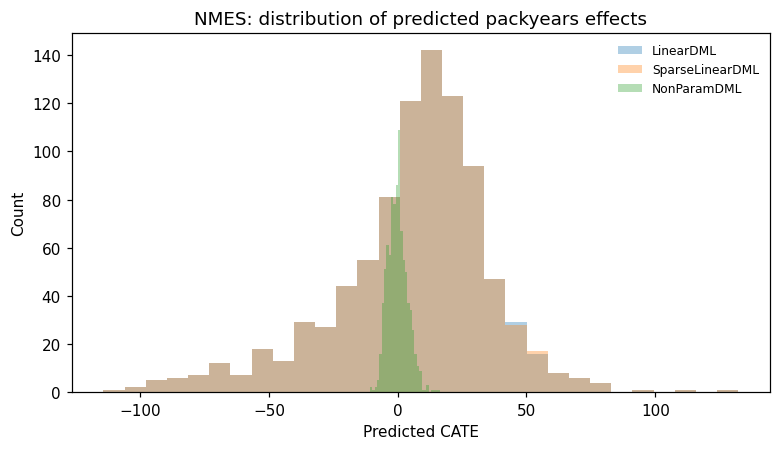

In [21]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for name, values in cate.items():
    ax.hist(values, bins=30, alpha=0.35, label=name)
ax.set_xlabel("Predicted CATE")
ax.set_ylabel("Count")
ax.set_title("NMES: distribution of predicted packyears effects")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


### 6.7 SHAP for Predicted CATE

`explain_cate` computes permutation SHAP for the `LinearDML` surface. Values are contributions to $\hat{\theta}(X)$, not to the scalar ATE.


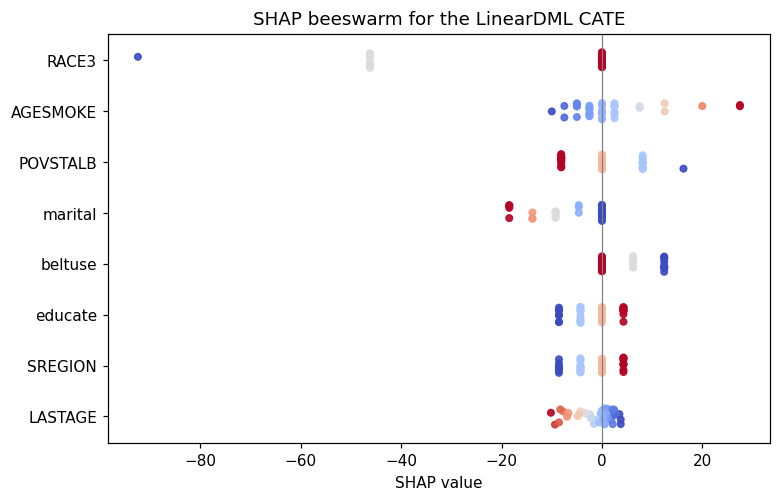

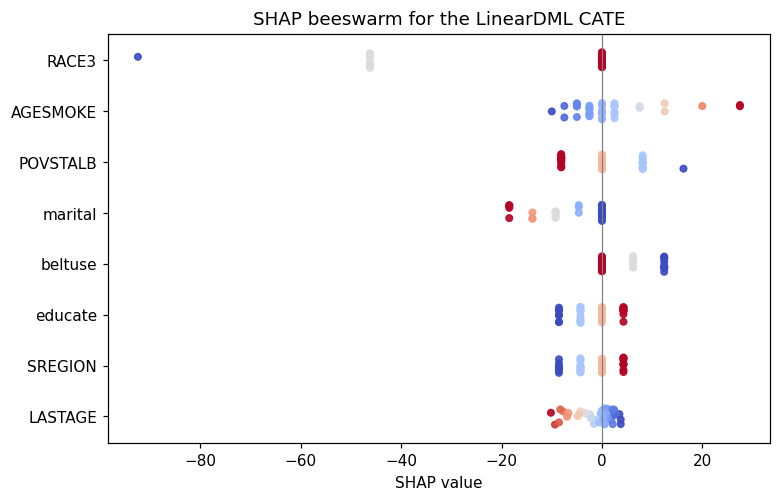

In [22]:
explanation = explain_cate(
    models["LinearDML"], X_nmes[te_n], feature_names=x_nmes_cols,
    max_samples=40, n_permutations=6, random_state=14,
)
plot_beeswarm(explanation, "SHAP beeswarm for the LinearDML CATE")


#### Beeswarm and bar importance


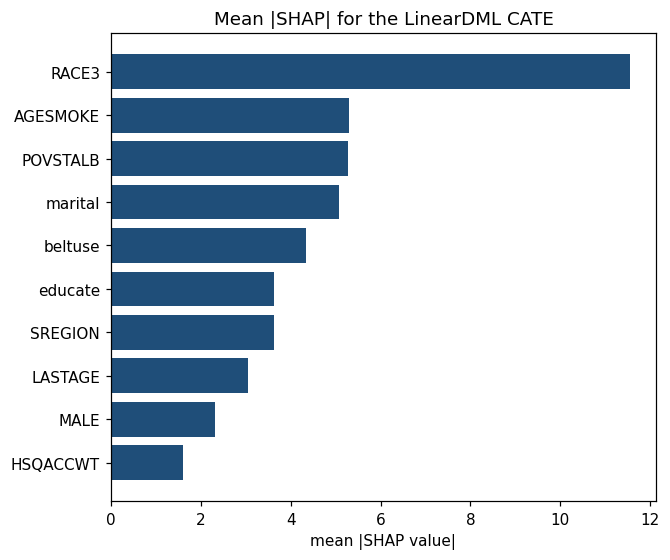

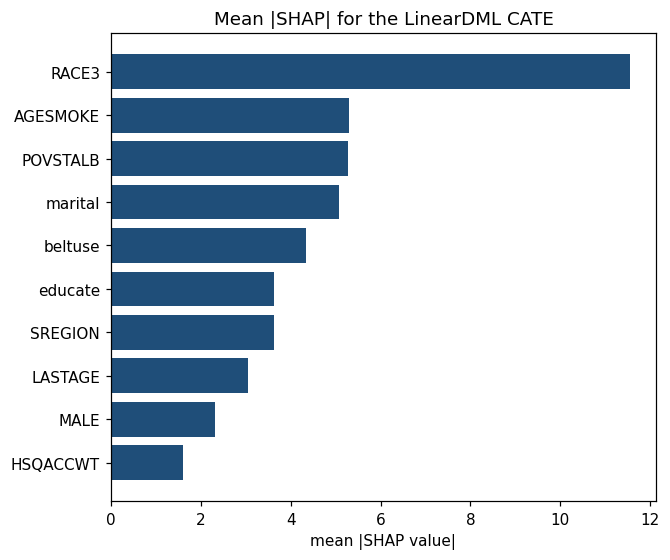

In [23]:
explanation.plot_importance(title="Mean |SHAP| for the LinearDML CATE")


#### SHAP dependence plots


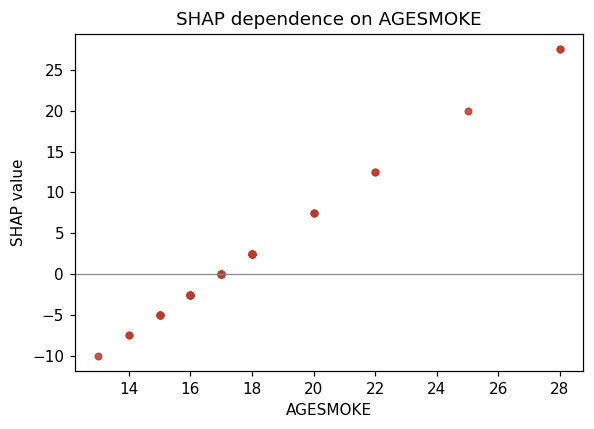

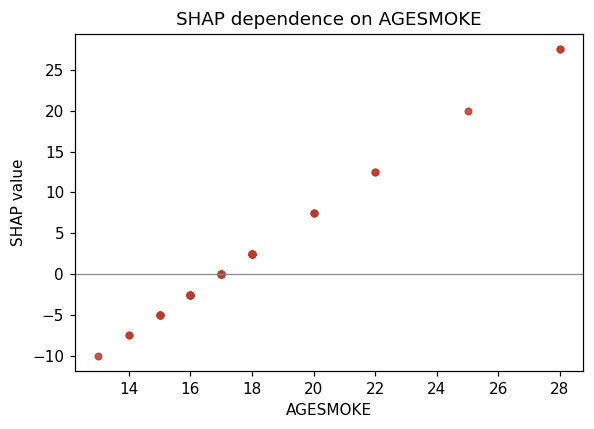

In [24]:
explanation.plot_dependence(x_nmes_cols[0], title=f"SHAP dependence on {x_nmes_cols[0]}")


#### SHAP for a single prediction


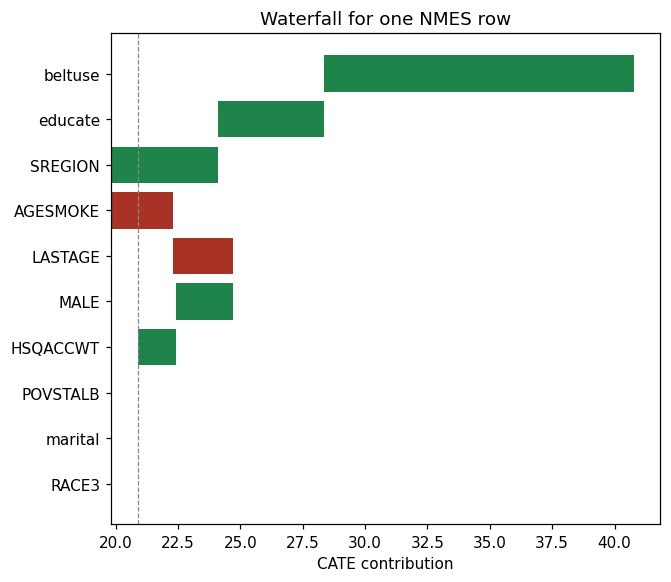

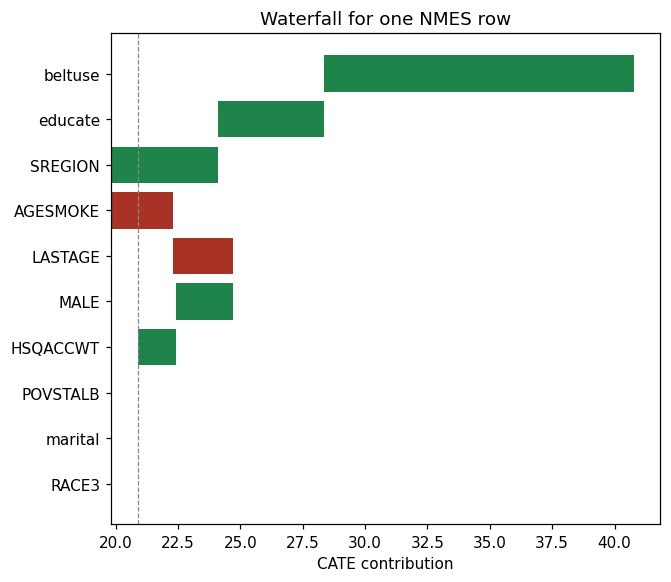

In [25]:
explanation.plot_waterfall(row=0, title="Waterfall for one NMES row")


##### Subgroup-specific SHAP


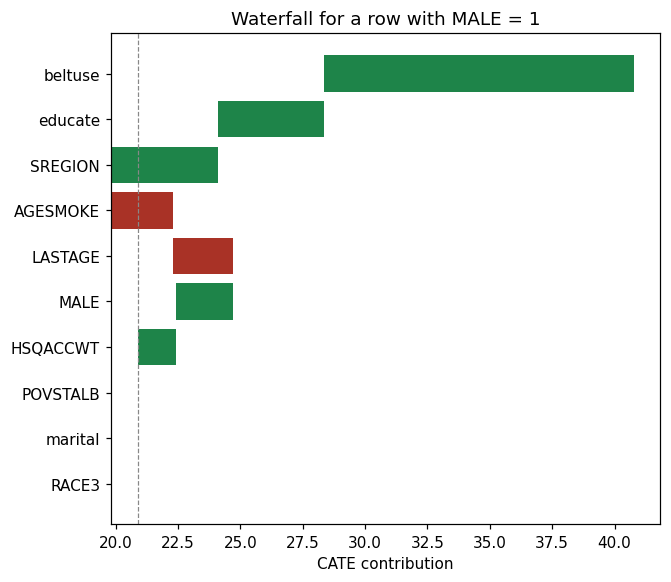

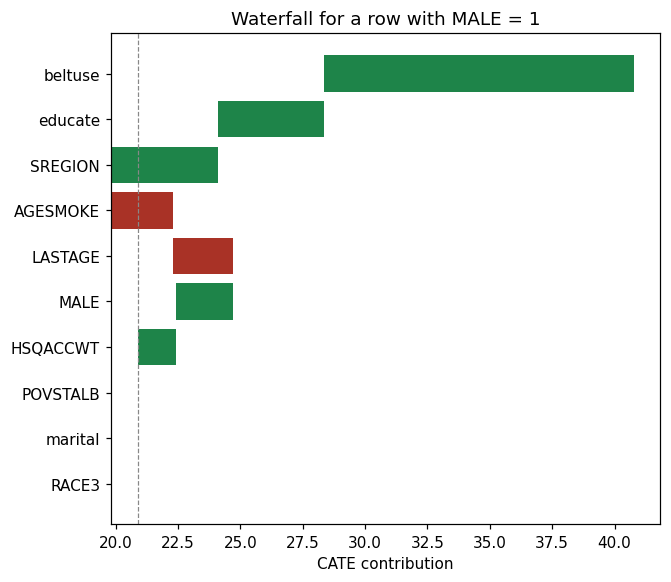

In [26]:
if "MALE" in explanation.feature_names:
    column = explanation.feature_names.index("MALE")
    hits = np.flatnonzero(np.asarray(explanation.data[:, column]) == 1)
    male_idx = int(hits[0]) if len(hits) else 0
else:
    male_idx = 0
explanation.plot_waterfall(row=male_idx, title="Waterfall for a row with MALE = 1")


## Summary and Conclusions

This notebook uses PyCausalML to estimate heterogeneous treatment effects for continuous and binary treatments, on synthetic data and on the NMES extract.

- **Section 1.** Continuous treatment. `LinearDML`, polynomial `SparseLinearDML`, and `NonParamDML`, selected by test-set CATE MSE.
- **Section 2.** Binary treatment. CATE curves and average effects with influence-function intervals, including `CausalForestDML`, `KernelDML`, and `InteractiveRegressionDML`.
- **Section 3.** `intercept_` and `feature_coef_` rebuild `predict`.
- **Sections 4 and 5.** NMES. One continuous exposure, then a joint residual regression for two exposures.
- **Section 6.** The same NMES sample, with agreement across final stages and SHAP on `LinearDML`.

## Resources

- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
- Battocchi, K., et al. EconML: a Python package for ML-based heterogeneous treatment effect estimation.
- The NMES extract is `Data/nmes_data.csv` (1987 National Medical Expenditure Survey).
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. NeurIPS.
